In [10]:
# 1. IMPORT LIBRARIES


import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
import ast
from pathlib import Path
sns.set_style('whitegrid')
from collections import Counter

warnings.filterwarnings('ignore', category=Warning)


In [9]:

# ============================================================
# 2. LOAD DATASETS
# ============================================================
DATA_DIR = Path.cwd().parent/ "data"

METADATA_FILE = DATA_DIR / "ptbxl_database.csv"
STATEMENTS_FILE = DATA_DIR / "scp_statements.csv"
df = pd.read_csv(METADATA_FILE)
df['scp_codes'] = df['scp_codes'].apply(ast.literal_eval) # string -> dict
scp = pd.read_csv(STATEMENTS_FILE, index_col=0)
# ============================================================
# CARDIOTRUSTAI - PTB-XL DATA EXPLORATION AND PREPROCESSING
# ============================================================


In [11]:
# ============================================================
# 3. BASIC DATA EXPLORATION
# ============================================================

print("Metadata Shape:", df.shape)
print("SCP Statements Shape:", scp.shape)

print("\nFirst Five ECG Records:")
display(df.head())

print("\nFirst Five SCP Statements:")
display(scp.head())

print("\nMetadata Columns:")
print(df.columns)

print("\nSCP Columns:")
print(scp.columns)

print("\nMetadata Information:")
df.info()

print("\nSCP Information:")
scp.info()

print("\nMetadata Statistical Summary:")
display(df.describe())

print("\nCategorical Statistical Summary:")
display(df.describe(include='object'))

print("\nSCP Statistical Summary:")
display(scp.describe(include='all'))

Metadata Shape: (21799, 28)
SCP Statements Shape: (71, 12)

First Five ECG Records:


,ecg_id,patient_id,age,sex,height,weight,nurse,site,device,recording_date,...,validated_by_human,baseline_drift,static_noise,burst_noise,electrodes_problems,extra_beats,pacemaker,strat_fold,filename_lr,filename_hr
0,1,15709.0,56.0,1,NaN,63.0,2.0,0.0,CS-12 E,1984-11-09 09:17:34,...,True,NaN,", I-V1,",NaN,NaN,NaN,NaN,3,records100/00000/00001_lr,records500/00000/00001_hr
1,2,13243.0,19.0,0,NaN,70.0,2.0,0.0,CS-12 E,1984-11-14 12:55:37,...,True,NaN,NaN,NaN,NaN,NaN,NaN,2,records100/00000/00002_lr,records500/00000/00002_hr
2,3,20372.0,37.0,1,NaN,69.0,2.0,0.0,CS-12 E,1984-11-15 12:49:10,...,True,NaN,NaN,NaN,NaN,NaN,NaN,5,records100/00000/00003_lr,records500/00000/00003_hr
3,4,17014.0,24.0,0,NaN,82.0,2.0,0.0,CS-12 E,1984-11-15 13:44:57,...,True,", II,III,AVF",NaN,NaN,NaN,NaN,NaN,3,records100/00000/00004_lr,records500/00000/00004_hr
4,5,17448.0,19.0,1,NaN,70.0,2.0,0.0,CS-12 E,1984-11-17 10:43:15,...,True,", III,AVR,AVF",NaN,NaN,NaN,NaN,NaN,4,records100/00000/00005_lr,records500/00000/00005_hr



First Five SCP Statements:


,description,diagnostic,form,rhythm,diagnostic_class,diagnostic_subclass,Statement Category,SCP-ECG Statement Description,AHA code,aECG REFID,CDISC Code,DICOM Code
NDT,non-diagnostic T abnormalities,1.0,1.0,NaN,STTC,STTC,other ST-T descriptive statements,non-diagnostic T abnormalities,NaN,NaN,NaN,NaN
NST_,non-specific ST changes,1.0,1.0,NaN,STTC,NST_,Basic roots for coding ST-T changes and abnorm...,non-specific ST changes,145.0,MDC_ECG_RHY_STHILOST,NaN,NaN
DIG,digitalis-effect,1.0,1.0,NaN,STTC,STTC,other ST-T descriptive statements,suggests digitalis-effect,205.0,NaN,NaN,NaN
LNGQT,long QT-interval,1.0,1.0,NaN,STTC,STTC,other ST-T descriptive statements,long QT-interval,148.0,NaN,NaN,NaN
NORM,normal ECG,1.0,NaN,NaN,NORM,NORM,Normal/abnormal,normal ECG,1.0,NaN,NaN,F-000B7



Metadata Columns:
Index(['ecg_id', 'patient_id', 'age', 'sex', 'height', 'weight', 'nurse',
       'site', 'device', 'recording_date', 'report', 'scp_codes', 'heart_axis',
       'infarction_stadium1', 'infarction_stadium2', 'validated_by',
       'second_opinion', 'initial_autogenerated_report', 'validated_by_human',
       'baseline_drift', 'static_noise', 'burst_noise', 'electrodes_problems',
       'extra_beats', 'pacemaker', 'strat_fold', 'filename_lr', 'filename_hr'],
      dtype='str')

SCP Columns:
Index(['description', 'diagnostic', 'form', 'rhythm', 'diagnostic_class',
       'diagnostic_subclass', 'Statement Category',
       'SCP-ECG Statement Description', 'AHA code', 'aECG REFID', 'CDISC Code',
       'DICOM Code'],
      dtype='str')

Metadata Information:
<class 'pandas.DataFrame'>
RangeIndex: 21799 entries, 0 to 21798
Data columns (total 28 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 

,ecg_id,patient_id,age,sex,height,weight,nurse,site,validated_by,strat_fold
count,21799.000000,21799.000000,21799.000000,21799.000000,6974.000000,9421.000000,20326.000000,21782.000000,12421.000000,21799.000000
mean,10926.658379,11250.156521,62.769301,0.479150,166.702323,70.995223,2.291745,1.544945,0.746075,5.503005
std,6302.393366,6235.026404,32.308813,0.499577,10.867321,15.878803,3.254033,4.172883,1.178003,2.874948
min,1.000000,302.000000,2.000000,0.000000,6.000000,5.000000,0.000000,0.000000,0.000000,1.000000
25%,5469.500000,5974.500000,50.000000,0.000000,160.000000,60.000000,0.000000,0.000000,0.000000,3.000000
50%,10926.000000,11419.000000,62.000000,0.000000,166.000000,70.000000,1.000000,1.000000,1.000000,6.000000
75%,16386.500000,16607.500000,72.000000,1.000000,174.000000,80.000000,3.000000,2.000000,1.000000,8.000000
max,21837.000000,21797.000000,300.000000,1.000000,209.000000,250.000000,11.000000,50.000000,11.000000,10.000000



Categorical Statistical Summary:


,device,recording_date,report,scp_codes,heart_axis,infarction_stadium1,infarction_stadium2,baseline_drift,static_noise,burst_noise,electrodes_problems,extra_beats,pacemaker,filename_lr,filename_hr
count,21799,21799,21799,21799,13331,5612,103,1598,3260,613,30,1949,291,21799,21799
unique,11,21795,9887,5298,8,6,3,317,124,103,14,128,4,21799,21799
top,CS100 3,1992-02-06 11:47:42,sinus rhythm. normal ecg.,"{'NORM': 100.0, 'SR': 0.0}",MID,unknown,Stadium III,", V6",", I-AVR,",alles,V6,1ES,"ja, pacemaker",records100/00000/00001_lr,records500/00000/00001_hr
freq,6140,2,1734,6142,7687,3430,65,221,953,140,8,405,285,1,1



SCP Statistical Summary:


,description,diagnostic,form,rhythm,diagnostic_class,diagnostic_subclass,Statement Category,SCP-ECG Statement Description,AHA code,aECG REFID,CDISC Code,DICOM Code
count,71,44.0,19.0,12.0,44,44,71,71,37.000000,23,13,13
unique,71,NaN,NaN,NaN,5,23,15,66,NaN,23,13,13
top,non-diagnostic T abnormalities,NaN,NaN,NaN,MI,IMI,Statements related to impulse formation (abnor...,in anterolateral leads,NaN,MDC_ECG_RHY_STHILOST,C71076,F-000B7
freq,1,NaN,NaN,NaN,14,6,10,2,NaN,1,1,1
mean,NaN,1.0,1.0,1.0,NaN,NaN,NaN,NaN,144.297297,NaN,NaN,NaN
std,NaN,0.0,0.0,0.0,NaN,NaN,NaN,NaN,119.739037,NaN,NaN,NaN
min,NaN,1.0,1.0,1.0,NaN,NaN,NaN,NaN,1.000000,NaN,NaN,NaN
25%,NaN,1.0,1.0,1.0,NaN,NaN,NaN,NaN,60.000000,NaN,NaN,NaN
50%,NaN,1.0,1.0,1.0,NaN,NaN,NaN,NaN,140.000000,NaN,NaN,NaN
75%,NaN,1.0,1.0,1.0,NaN,NaN,NaN,NaN,162.000000,NaN,NaN,NaN


In [15]:

# ============================================================
# 4. CHECK MISSING VALUES
# ============================================================

print("\nMissing Values Per Column:")
print(df.isnull().sum())

print("\nTotal Missing Values:")
print(df.isnull().sum().sum())

# print("\nMissing Value Percentage:")

# missing_percentage = (df.isnull().sum() / len(df)) * 100

# print(missing_percentage.sort_values(ascending=False))

print("\nSCP Missing Values:")
print(scp.isnull().sum())

# plt.figure(figsize=(15, 6))

# sns.heatmap(df.isnull(), cbar=False)

# plt.title("Missing Values in PTB-XL Metadata")

# plt.show()




Missing Values Per Column:
ecg_id                              0
patient_id                          0
age                                 0
sex                                 0
height                          14825
weight                          12378
nurse                            1473
site                               17
device                              0
recording_date                      0
report                              0
scp_codes                           0
heart_axis                       8468
infarction_stadium1             16187
infarction_stadium2             21696
validated_by                     9378
second_opinion                      0
initial_autogenerated_report        0
validated_by_human                  0
baseline_drift                  20201
static_noise                    18539
burst_noise                     21186
electrodes_problems             21769
extra_beats                     19850
pacemaker                       21508
strat_fold            

In [16]:
# ============================================================
# 5. CHECK DUPLICATE RECORDS
# ============================================================

print("\nDuplicate ECG IDs:")
print(df['ecg_id'].duplicated().sum())

print("\nDuplicate Patient IDs:")
print(df['patient_id'].duplicated().sum())

print("\nUnique Patients:")
print(df['patient_id'].nunique())

print("\nDuplicate ECG Records:")
display(df[df['ecg_id'].duplicated(keep=False)])


Duplicate ECG IDs:
0

Duplicate Patient IDs:
2930

Unique Patients:
18869

Duplicate ECG Records:


,ecg_id,patient_id,age,sex,height,weight,nurse,site,device,recording_date,...,validated_by_human,baseline_drift,static_noise,burst_noise,electrodes_problems,extra_beats,pacemaker,strat_fold,filename_lr,filename_hr


In [17]:
# ============================================================
# 6. IDENTIFY NUMERICAL AND CATEGORICAL COLUMNS
# ============================================================

numerical_columns = df.select_dtypes(
    include=np.number
).columns.tolist()

categorical_columns = df.select_dtypes(
    include=['object', 'category', 'str']
).columns.tolist()

print("\nNumerical Columns:")
print(numerical_columns)

print("\nCategorical Columns:")
print(categorical_columns)


Numerical Columns:
['ecg_id', 'patient_id', 'age', 'sex', 'height', 'weight', 'nurse', 'site', 'validated_by', 'strat_fold']

Categorical Columns:
['device', 'recording_date', 'report', 'scp_codes', 'heart_axis', 'infarction_stadium1', 'infarction_stadium2', 'baseline_drift', 'static_noise', 'burst_noise', 'electrodes_problems', 'extra_beats', 'pacemaker', 'filename_lr', 'filename_hr']


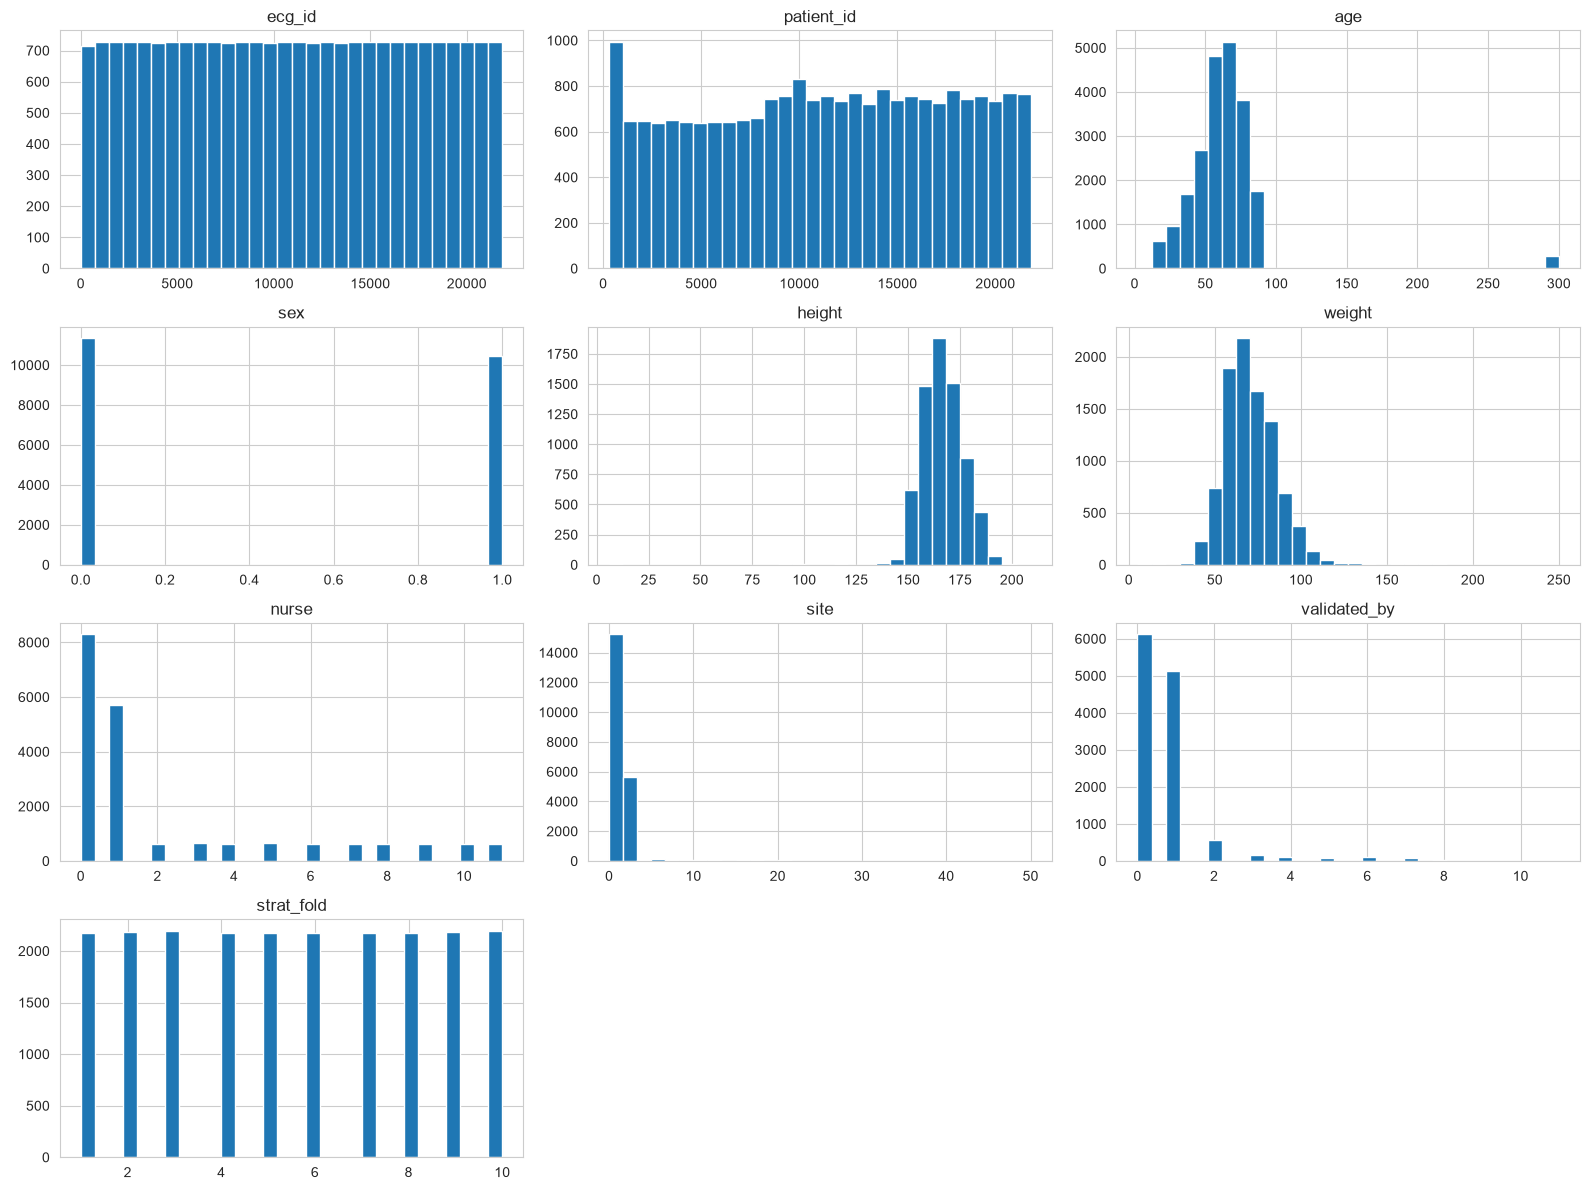

In [18]:

# ============================================================
# 7. NUMERICAL FEATURE DISTRIBUTION
# ============================================================

df[numerical_columns].hist(
    figsize=(16, 12),
    bins=30
)

plt.tight_layout()

plt.show()


In [5]:






# ============================================================
# 7. NUMERICAL FEATURE DISTRIBUTION
# ============================================================

df[numerical_columns].hist(
    figsize=(16, 12),
    bins=30
)

plt.tight_layout()

plt.show()


# ============================================================
# 8. CATEGORICAL FEATURE DISTRIBUTION
# ============================================================

for col in ['sex', 'site', 'device']:

    if col in df.columns:

        plt.figure(figsize=(12, 5))

        sns.countplot(
            data=df,
            x=col,
            order=df[col].value_counts().index
        )

        plt.title(f"Distribution of {col}")

        plt.xticks(rotation=45)

        plt.tight_layout()

        plt.show()


# ============================================================
# 9. OUTLIER ANALYSIS
# ============================================================

plt.figure(figsize=(12, 6))

sns.boxplot(
    data=df[['age', 'height', 'weight']]
)

plt.title("Outlier Analysis")

plt.show()


# ============================================================
# 10. CREATE A CLEANED DATAFRAME
# ============================================================

df_clean = df.copy()


# ============================================================
# 11. CLEAN AGE
# ============================================================

print("\nAge Statistics Before Cleaning:")
print(df_clean['age'].describe())

print("\nInvalid Age Values:")

display(df_clean.loc[df_clean['age'] > 100, ['ecg_id', 'age']])

df_clean.loc[
    (df_clean['age'] < 0) | (df_clean['age'] > 100),
    'age'
] = np.nan

print("\nAge Statistics After Cleaning:")
print(df_clean['age'].describe())


# ============================================================
# 12. CLEAN HEIGHT
# ============================================================

print("\nHeight Statistics Before Cleaning:")
print(df_clean['height'].describe())

df_clean.loc[
    (df_clean['height'] < 100) |
    (df_clean['height'] > 220),
    'height'
] = np.nan

print("\nHeight Statistics After Cleaning:")
print(df_clean['height'].describe())


# ============================================================
# 13. CLEAN WEIGHT
# ============================================================

print("\nWeight Statistics Before Cleaning:")
print(df_clean['weight'].describe())

df_clean.loc[
    (df_clean['weight'] < 20) |
    (df_clean['weight'] > 200),
    'weight'
] = np.nan

print("\nWeight Statistics After Cleaning:")
print(df_clean['weight'].describe())


# ============================================================
# 14. CHECK CLEANED MISSING VALUES
# ============================================================

print("\nMissing Values After Cleaning:")

print(df_clean.isnull().sum())


# ============================================================
# 15. CORRELATION ANALYSIS
# ============================================================

correlation_columns = [
    'age',
    'height',
    'weight'
]

correlation = df_clean[correlation_columns].corr()

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title("Correlation Between Patient Features")

plt.show()


# ============================================================
# 16. PARSE SCP DIAGNOSTIC CODES
# ============================================================

def parse_scp_codes(value):

    if pd.isna(value):
        return {}

    try:

        result = ast.literal_eval(value)

        if isinstance(result, dict):
            return result

        return {}

    except (ValueError, SyntaxError):

        return {}


df_clean['scp_codes_dict'] = df_clean['scp_codes'].apply(
    parse_scp_codes
)

print("\nParsed SCP Codes:")

display(
    df_clean[['scp_codes', 'scp_codes_dict']].head()
)


# ============================================================
# 17. EXPLORE SCP STATEMENTS
# ============================================================

print("\nSCP Statement Columns:")
print(scp.columns)

print("\nDiagnostic Statement Distribution:")

print(
    scp['diagnostic'].value_counts(dropna=False)
)

print("\nDiagnostic Class Distribution:")

print(
    scp['diagnostic_class'].value_counts(dropna=False)
)


# ============================================================
# 18. MAP SCP CODES TO DIAGNOSTIC CLASSES
# ============================================================

diagnostic_map = scp.loc[
    scp['diagnostic'] == 1,
    'diagnostic_class'
].to_dict()


def get_diagnostic_classes(codes):

    classes = set()

    for code in codes:

        diagnostic_class = diagnostic_map.get(code)

        if pd.notna(diagnostic_class):

            classes.add(diagnostic_class)

    return sorted(classes)


df_clean['diagnostic_classes'] = (
    df_clean['scp_codes_dict'].apply(get_diagnostic_classes)
)

print("\nDiagnostic Classes:")

display(
    df_clean[['scp_codes_dict', 'diagnostic_classes']].head(10)
)


# ============================================================
# 19. COUNT DIAGNOSTIC CLASSES
# ============================================================

class_counts = Counter(
    label
    for labels in df_clean['diagnostic_classes']
    for label in labels
)

class_counts = pd.Series(class_counts).sort_values(
    ascending=False
)

print("\nDiagnostic Class Counts:")

print(class_counts)

plt.figure(figsize=(10, 6))

sns.barplot(
    x=class_counts.index,
    y=class_counts.values
)

plt.title("PTB-XL Diagnostic Class Distribution")

plt.xlabel("Diagnostic Class")

plt.ylabel("Number of ECG Recordings")

plt.show()


# ============================================================
# 20. CREATE BINARY CLASSIFICATION TARGET
# ============================================================

abnormal_classes = {
    'MI',
    'STTC',
    'CD',
    'HYP'
}


def create_binary_target(classes):

    if not classes:
        return np.nan

    return int(
        any(label in abnormal_classes for label in classes)
    )


df_clean['abnormal_ecg'] = (
    df_clean['diagnostic_classes'].apply(create_binary_target)
)

print("\nBinary Target Distribution:")

print(
    df_clean['abnormal_ecg'].value_counts(dropna=False)
)

plt.figure(figsize=(7, 5))

sns.countplot(
    data=df_clean,
    x='abnormal_ecg'
)

plt.title("Normal vs Abnormal ECG Recordings")

plt.xlabel("Abnormal ECG (0 = Normal, 1 = Abnormal)")

plt.show()


# ============================================================
# 21. PREPARE MODEL FEATURES
# ============================================================

feature_columns = [
    'age',
    'sex',
    'height',
    'weight'
]

df_model = df_clean.loc[
    df_clean['abnormal_ecg'].notna()
].copy()

X = df_model[feature_columns].copy()

y = df_model['abnormal_ecg'].astype(int)

print("\nFeature Shape:", X.shape)

print("\nTarget Shape:", y.shape)

print("\nTarget Distribution:")

print(y.value_counts())


# ============================================================
# 22. SPLIT DATA USING OFFICIAL PTB-XL FOLDS
# ============================================================

train_df = df_model[
    df_model['strat_fold'].between(1, 8)
].copy()

val_df = df_model[
    df_model['strat_fold'] == 9
].copy()

test_df = df_model[
    df_model['strat_fold'] == 10
].copy()

print("\nTraining Shape:", train_df.shape)

print("Validation Shape:", val_df.shape)

print("Testing Shape:", test_df.shape)


# ============================================================
# 23. CHECK PATIENT DATA LEAKAGE
# ============================================================

train_patients = set(train_df['patient_id'])

val_patients = set(val_df['patient_id'])

test_patients = set(test_df['patient_id'])

print("\nTrain and Validation Overlap:")

print(len(train_patients & val_patients))

print("\nTrain and Test Overlap:")

print(len(train_patients & test_patients))

print("\nValidation and Test Overlap:")

print(len(val_patients & test_patients))


# ============================================================
# 24. PREPARE TRAINING, VALIDATION AND TEST FEATURES
# ============================================================

X_train = train_df[feature_columns].copy()

X_val = val_df[feature_columns].copy()

X_test = test_df[feature_columns].copy()

y_train = train_df['abnormal_ecg'].astype(int)

y_val = val_df['abnormal_ecg'].astype(int)

y_test = test_df['abnormal_ecg'].astype(int)


# ============================================================
# 25. HANDLE MISSING VALUES
# ============================================================

from sklearn.impute import SimpleImputer

numerical_features = [
    'age',
    'height',
    'weight'
]

imputer = SimpleImputer(
    strategy='median'
)

X_train[numerical_features] = imputer.fit_transform(
    X_train[numerical_features]
)

X_val[numerical_features] = imputer.transform(
    X_val[numerical_features]
)

X_test[numerical_features] = imputer.transform(
    X_test[numerical_features]
)


# ============================================================
# 26. FEATURE SCALING
# ============================================================

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train[numerical_features] = scaler.fit_transform(
    X_train[numerical_features]
)

X_val[numerical_features] = scaler.transform(
    X_val[numerical_features]
)

X_test[numerical_features] = scaler.transform(
    X_test[numerical_features]
)


# ============================================================
# 27. FINAL DATA CHECK
# ============================================================

print("\nFinal Training Features:")

display(X_train.head())

print("\nFinal Validation Features:")

display(X_val.head())

print("\nFinal Testing Features:")

display(X_test.head())

print("\nFinal Dataset Shapes:")

print("X_train:", X_train.shape)

print("X_val:", X_val.shape)

print("X_test:", X_test.shape)

print("y_train:", y_train.shape)

print("y_val:", y_val.shape)

print("y_test:", y_test.shape)

print("\nMissing Values in Training:")

print(X_train.isnull().sum())

print("\nMissing Values in Validation:")

print(X_val.isnull().sum())

print("\nMissing Values in Testing:")

print(X_test.isnull().sum())

(21799, 28)


Index(['ecg_id', 'patient_id', 'age', 'sex', 'height', 'weight', 'nurse',
       'site', 'device', 'recording_date', 'report', 'scp_codes', 'heart_axis',
       'infarction_stadium1', 'infarction_stadium2', 'validated_by',
       'second_opinion', 'initial_autogenerated_report', 'validated_by_human',
       'baseline_drift', 'static_noise', 'burst_noise', 'electrodes_problems',
       'extra_beats', 'pacemaker', 'strat_fold', 'filename_lr', 'filename_hr'],
      dtype='str')

In [6]:
print(scp.shape) 
scp.head()

scp.columns

(71, 12)


Index(['description', 'diagnostic', 'form', 'rhythm', 'diagnostic_class',
       'diagnostic_subclass', 'Statement Category',
       'SCP-ECG Statement Description', 'AHA code', 'aECG REFID', 'CDISC Code',
       'DICOM Code'],
      dtype='str')

In [8]:
df.isnull().sum()

ecg_id                              0
patient_id                          0
age                                 0
sex                                 0
height                          14825
weight                          12378
nurse                            1473
site                               17
device                              0
recording_date                      0
report                              0
scp_codes                           0
heart_axis                       8468
infarction_stadium1             16187
infarction_stadium2             21696
validated_by                     9378
second_opinion                      0
initial_autogenerated_report        0
validated_by_human                  0
baseline_drift                  20201
static_noise                    18539
burst_noise                     21186
electrodes_problems             21769
extra_beats                     19850
pacemaker                       21508
strat_fold                          0
filename_lr 

In [11]:
df['patient_id'].duplicated().sum()

np.int64(2930)

In [12]:
df['ecg_id'].duplicated().sum()

np.int64(0)

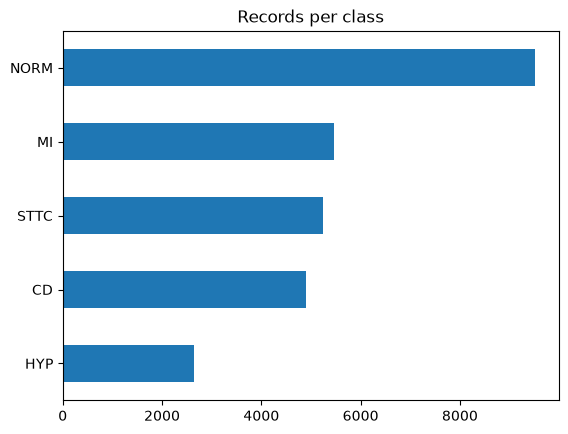

ecg_id                              0
patient_id                          0
age                                 0
sex                                 0
height                          14825
weight                          12378
nurse                            1473
site                               17
device                              0
recording_date                      0
report                              0
scp_codes                           0
heart_axis                       8468
infarction_stadium1             16187
infarction_stadium2             21696
validated_by                     9378
second_opinion                      0
initial_autogenerated_report        0
validated_by_human                  0
baseline_drift                  20201
static_noise                    18539
burst_noise                     21186
electrodes_problems             21769
extra_beats                     19850
pacemaker                       21508
strat_fold                          0
filename_lr 

In [6]:
df.isnull().sum()

In [11]:
df['patient_id'].duplicated().sum()

np.int64(2930)

In [12]:
df['ecg_id'].duplicated().sum()

np.int64(0)